# HEALPix mosaic (compressed) versus the UTM sources — T31UDQ + T31UDR, 12 August 2026

Mosaic: `s3://grid4earth/test-compression/mosaic_20260812_R051/r10m/mosaic.zarr`, Sentinel-2B, relative orbit 51, 10 m bands (B02, B03, B04, B08), HEALPix level 20 (nested, WGS84), codec `hcc-sentinel2-pyramid`.

The mosaic joins two MGRS tiles. Each level-11 parent cell (one chunk of the store) comes from exactly one tile, recorded in `state.json` (`owner`). The UTM reference is therefore built pixel by pixel from the tile that owns the parent cell of the pixel.

| Name | Location | Content |
|---|---|---|
| **UTM** | the two L2A source products, read directly from the EOPF service | `uint16` digital numbers on the UTM 31N 10 m grid, converted to reflectance |
| **HEALPix compressed** | `mosaic.zarr` | reflectance at level 20, `hcc-sentinel2-pyramid` codec |
| **HEALPix raw (recomputed)** | computed in this notebook | the uncompressed HEALPix field, recomputed from the UTM data with the conversion's `PSFResampler` settings |

**Why a recomputed raw field.** Unlike the single-tile test, the mosaic has no uncompressed companion store. The uncompressed field is recomputed locally from the UTM patch, enlarged by a 16-pixel margin, with the same resampler parameters as the conversion. This was validated on the 13 June 2025 T31UDQ product, which does have a stored uncompressed field: inside the patch, the recomputed cells match the stored ones to 2·10⁻⁷ in reflectance RMS (maximum 7·10⁻⁵), about a thousand times below the codec error. Only cells near the enlarged window edge differ, and they are not used.

All values are **surface reflectance** (dimensionless): `reflectance = DN × 1e-4 − 0.1`. An error of 0.001 in reflectance equals 10 DN.

Outline:
1. Find the two UTM products in the EOPF STAC catalogue.
2. Mosaic store: chunk map and **written coverage** (the mosaic is not complete on S3).
3. **Visual check** on 4 patches of 512×512 UTM pixels.
4. **HEALPix → UTM reprojection** with `PSFResampler`, residuals against the UTM data.
5. **Radial power spectra** of the residuals.

Run with the **Python (venv-hc)** kernel under WSL, AWS profile `default`, OVH GRA endpoint.

In [1]:
import sys, json, time, logging
from concurrent.futures import ThreadPoolExecutor

# The healpix-compress repo has its own `hcc/` folder: make sure we import the
# healpix-compress-s2 package (which provides the hcc-sentinel2-pyramid codec).
sys.path = [p for p in sys.path if not p.rstrip("/").endswith("healpix-compress")]
import hcc
assert "healpix-compress-s2" in hcc.__file__, hcc.__file__

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import pyproj, s3fs, torch, zarr, zarr.storage, pystac_client
from zarr.registry import register_codec
from hcc.codecs.sentinel2_pyramid import HccSentinel2PyramidCodec
from healpix_geo.nested import lonlat_to_healpix, healpix_to_lonlat
from healpix_resample.psf import PSFResampler

register_codec("hcc-sentinel2-pyramid", HccSentinel2PyramidCodec)
logging.getLogger("asyncio").setLevel(logging.CRITICAL)
import warnings; warnings.filterwarnings("ignore", category=UserWarning, module="healpix_resample")
torch.set_num_threads(16)
plt.rcParams.update({"figure.dpi": 72, "image.interpolation": "nearest"})   # 72 dpi keeps the notebook small enough for GitHub

ROOT = "grid4earth/test-compression/mosaic_20260812_R051/r10m"
BANDS = ["b02", "b03", "b04", "b08"]
N, MB, DX = 512, 16, 10.0          # patch size (px), margin for the local raw recompute (px), pixel size (m)
EP = dict(profile="default", endpoint_url="https://s3.gra.io.cloud.ovh.net", client_kwargs={"region_name": "gra"})
fs = s3fs.S3FileSystem(skip_instance_cache=True, **EP)
afs = s3fs.S3FileSystem(asynchronous=True, **EP)
open_group = lambda p: zarr.open_group(zarr.storage.FsspecStore(afs, path=p, read_only=True), mode="r")
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

torch 2.14.1+cpu | cuda: False


## 1. UTM source products (EOPF)

The mosaic's STAC metadata gives the acquisition (Sentinel-2B, 2026-08-12 10:46 UTC, relative orbit 51). The matching L2A products of both tiles are searched in the EOPF STAC catalogue and read directly over HTTPS.

In [2]:
meta = json.loads(fs.cat(f"{ROOT}/mosaic.zarr/zarr.json"))
props = meta["attributes"]["stac_discovery"]["properties"]
DATE = props["datetime"][:10]
print("mosaic:", props["platform"], props["datetime"], "relative orbit", props["sat:relative_orbit"],
      "| datatake", props["eopf:datatake_id"])
RES = props["processing:expression"]["expression"]["group_settings"]["measurements/reflectance/r10m"]["resampler"]
print("resampler used by the conversion:", RES)

state = json.loads(fs.cat(f"{ROOT}/state.json"))
TILES = state["fetched"]
cat = pystac_client.Client.open("https://stac.core.eopf.eodc.eu")
utm = {}
for tile in TILES:
    src = json.loads(fs.cat(f"{ROOT}/{tile}_source.json"))
    lon_t, lat_t = np.mean(src["_geometry"]["coordinates"][0][:-1], axis=0)
    items = [it for it in cat.search(collections=["sentinel-2-l2a"], bbox=[lon_t - .01, lat_t - .01, lon_t + .01, lat_t + .01],
                                     datetime=DATE).items()
             if tile in it.id and it.properties.get("platform") == props["platform"]
             and it.properties.get("sat:relative_orbit") == props["sat:relative_orbit"]]
    assert len(items) == 1, [i.id for i in items]
    href = items[0].assets["product"].href
    g = zarr.open_group(zarr.storage.FsspecStore.from_url(href + "/measurements/reflectance/r10m", read_only=True), mode="r")
    a = g["b04"].attrs
    utm[tile] = dict(id=items[0].id, group=g, x=g["x"][:], y=g["y"][:],
                     scale=float(a["scale_factor"]), offset=float(a["add_offset"]))
    print(f"{tile}: {items[0].id}  (cloud {items[0].properties['eo:cloud_cover']:.3f}%)\n        {href}")

mosaic: sentinel-2b 2026-08-12T10:46:19.024000Z relative orbit 51 | datatake GS2B_20260812T104619_049269_N05.12
resampler used by the conversion: {'init_params': {'Npt': 9, 'threshold': 0.1}, 'resample_params': {'lam': 0.1, 'max_iter': 100, 'tol': 1e-08}, 'name': 'psf'}


T31UDQ: S2B_MSIL2A_20260812T104619_N0512_R051_T31UDQ_20260812T131957  (cloud 0.002%)
        https://data.eodc.eu/collections/EOPF_ZARR/products/cpm_v270/S02MSIL2A/2026/08/12/S2B_MSIL2A_20260812T104619_N0512_R051_T31UDQ_20260812T131957.zarr


T31UDR: S2B_MSIL2A_20260812T104619_N0512_R051_T31UDR_20260812T131957  (cloud 0.002%)
        https://objects.eodc.eu:443/e05ab01a9d56408d82ac32d69a5aae2a:202608-s02msil2a-eu/12/products/cpm_v270/S2B_MSIL2A_20260812T104619_N0512_R051_T31UDR_20260812T131957.zarr


## 2. Mosaic store and written coverage

`state.json` maps each level-11 parent cell to its chunk (`pos`) and to the tile it comes from (`owner`). The chunks actually present on S3 are listed, because the mosaic upload is not complete: missing chunks would read as fill values.

628,359,168 cells in 2397 chunks of 262144; chunks written for all arrays: 909 (37.9%)
   T31UDQ: 855/1277 parent cells written
   T31UDR: 54/1120 parent cells written


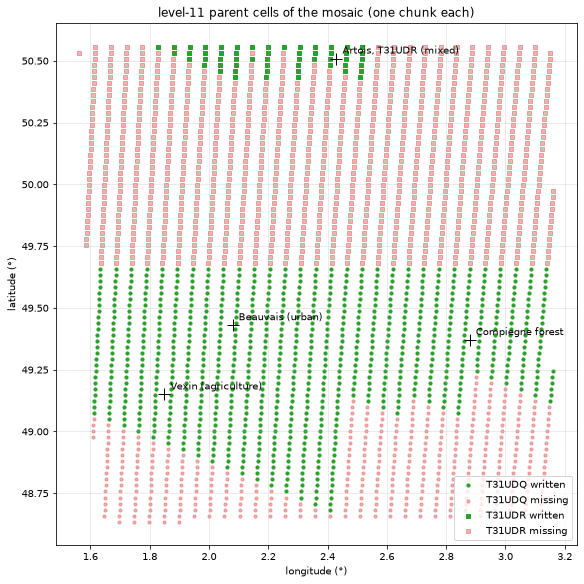

In [3]:
mos = open_group(f"{ROOT}/mosaic.zarr/measurements/reflectance/20")
cid = mos["cell_ids"]
CS, NCH = cid.chunks[0], cid.nchunks
pos = {int(k): v for k, v in state["pos"].items()}
owner = {int(k): v for k, v in state["owner"].items()}
written = None
for b in ["cell_ids"] + BANDS:
    keys = {int(k.rsplit("/", 1)[1]) for k in fs.ls(f"{ROOT}/mosaic.zarr/measurements/reflectance/20/{b}/c", refresh=True)}
    written = keys if written is None else written & keys
print(f"{cid.shape[0]:,} cells in {NCH} chunks of {CS}; chunks written for all arrays: {len(written)} "
      f"({100 * len(written) / NCH:.1f}%)")
for t in TILES:
    n_all = sum(o == t for o in owner.values())
    n_w = sum(o == t and pos[p] in written for p, o in owner.items())
    print(f"   {t}: {n_w}/{n_all} parent cells written")

SITES = {   # (lon, lat) of the patch centre, chosen inside the written area
    "Beauvais (urban)":           (2.0800, 49.4300),
    "Compiegne forest":           (2.8800, 49.3700),
    "Vexin (agriculture)":        (1.8500, 49.1500),
    "Artois, T31UDR (mixed)":     (2.4300, 50.5090),
}

par = np.array(sorted(pos), dtype=np.uint64)
plon, plat = (np.asarray(v) for v in healpix_to_lonlat(par, 11, ellipsoid="WGS84"))
w = np.array([pos[int(p)] in written for p in par])
fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)
for t, m in zip(TILES, "os"):
    s = np.array([owner[int(p)] == t for p in par])
    ax.scatter(plon[s & w], plat[s & w], s=10, marker=m, c="C2", label=f"{t} written")
    ax.scatter(plon[s & ~w], plat[s & ~w], s=10, marker=m, c="C3", alpha=0.35, label=f"{t} missing")
for k, (x0, y0) in SITES.items():
    ax.plot(x0, y0, "k+", ms=12); ax.text(x0 + 0.02, y0 + 0.02, k)
ax.set_xlabel("longitude (°)"); ax.set_ylabel("latitude (°)"); ax.grid(alpha=0.3); ax.legend(loc="lower right")
ax.set_title("level-11 parent cells of the mosaic (one chunk each)")
plt.show()

## 3. Patch extraction and local raw recompute

For each patch:
- the UTM window (patch plus a 16-pixel margin) is read from every tile that owns one of its parent cells, and each pixel takes the value of its owner tile;
- the compressed cells are read from the mosaic chunks of all parent cells touching the window (the patch is skipped if one of them is missing);
- the uncompressed HEALPix field is recomputed from the enlarged UTM window with `PSFResampler.resample`, using the conversion's parameters. Only cells inside the patch are used afterwards, away from the window edge.

In [4]:
to_wgs = pyproj.Transformer.from_crs(32631, 4326, always_xy=True)
to_utm = pyproj.Transformer.from_crs(4326, 32631, always_xy=True)
ref = utm[TILES[0]]                        # both tiles share the UTM 31N 10 m grid

def read_chunks(arr, chunks):
    with ThreadPoolExecutor(16) as ex:
        return np.concatenate(list(ex.map(lambda c: arr[c * CS:(c + 1) * CS], chunks)))

def utm_window(tile, xs, ys):
    # reflectance of `tile` on the (ys, xs) pixel grid; NaN where the tile has no data or does not cover it
    u = utm[tile]
    j = int(round((xs[0] - u["x"][0]) / DX)); i = int(round((u["y"][0] - ys[0]) / DX))
    out = np.full((len(BANDS), ys.size, xs.size), np.nan)
    i0, i1 = max(i, 0), min(i + ys.size, u["y"].size)
    j0, j1 = max(j, 0), min(j + xs.size, u["x"].size)
    if i0 >= i1 or j0 >= j1:
        return out
    with ThreadPoolExecutor(4) as ex:
        dn = np.stack(list(ex.map(lambda b: u["group"][b][i0:i1, j0:j1], BANDS))).astype(float)
    out[:, i0 - i:i1 - i, j0 - j:j1 - j] = np.where(dn == 0, np.nan, dn * u["scale"] + u["offset"])
    return out

def load_patch(name, lon0, lat0):
    t = time.time()
    xc, yc = to_utm.transform(lon0, lat0)
    j0 = int(round((xc - ref["x"][0]) / DX)) - N // 2 - MB
    i0 = int(round((ref["y"][0] - yc) / DX)) - N // 2 - MB
    xs = ref["x"][0] + DX * np.arange(j0, j0 + N + 2 * MB)
    ys = ref["y"][0] - DX * np.arange(i0, i0 + N + 2 * MB)
    XX, YY = np.meshgrid(xs, ys)
    LON, LAT = to_wgs.transform(XX, YY)
    parent = (np.asarray(lonlat_to_healpix(LON.ravel(), LAT.ravel(), 11, ellipsoid="WGS84"))).reshape(XX.shape)
    parents = np.unique(parent)
    missing = [p for p in parents if p not in pos or pos[p] not in written]
    if missing:
        print(f"{name:30s} SKIPPED: {len(missing)}/{parents.size} parent cells not written")
        return None
    # UTM reference, pixel by pixel from the owner tile (the other tile fills pixels the owner does not cover)
    own = np.vectorize(owner.get)(parent)
    wins = {tile: utm_window(tile, xs, ys) for tile in TILES}
    refl = np.full((len(BANDS),) + XX.shape, np.nan)
    for tile in TILES:
        m = own == tile
        refl[:, m] = wins[tile][:, m]
    for tile in TILES:
        gap = np.isnan(refl)
        refl[gap] = wins[tile][gap]
    if np.isnan(refl).mean() > 0.01:
        print(f"{name:30s} SKIPPED: {np.isnan(refl).mean() * 100:.1f}% of the window has no UTM data")
        return None
    # compressed HEALPix cells
    chunks = [pos[p] for p in parents]
    cells = read_chunks(cid, chunks)
    codec = np.stack([read_chunks(mos[b], chunks) for b in BANDS])
    o = np.argsort(cells); cells, codec = cells[o], codec[:, o]
    # local recompute of the uncompressed field on the enlarged window
    Rb = PSFResampler(LON.ravel(), LAT.ravel(), level=20, device="cpu", dtype=torch.float64, verbose=False,
                      **RES["init_params"])
    rr = Rb.resample(refl.reshape(len(BANDS), -1), **RES["resample_params"])
    rcells = np.asarray(rr.cell_ids).astype(np.uint64); rvals = np.asarray(rr.cell_data)
    o = np.argsort(rcells); rcells, rvals = rcells[o], rvals[:, o]
    del Rb
    inner = (slice(MB, MB + N), slice(MB, MB + N))
    lon, lat = LON[inner], LAT[inner]
    P = dict(name=name, lon0=lon0, lat0=lat0, utm=refl[:, inner[0], inner[1]], lon=lon, lat=lat,
             owner_tiles=sorted(str(s) for s in np.unique(own[inner])), cells=cells, codec=codec, rcells=rcells, rvals=rvals,
             own=own[inner], parent=parent[inner], utm_tiles={t: w[:, inner[0], inner[1]] for t, w in wins.items()})
    # cell containing each UTM pixel centre (no interpolation)
    nc = np.asarray(lonlat_to_healpix(lon.ravel(), lat.ravel(), 20, ellipsoid="WGS84")).astype(np.uint64)
    pc, pr = np.searchsorted(cells, nc), np.searchsorted(rcells, nc)
    assert np.all(cells[np.minimum(pc, cells.size - 1)] == nc) and np.all(rcells[np.minimum(pr, rcells.size - 1)] == nc)
    P["nearest"] = {"raw": rvals[:, pr].reshape(len(BANDS), N, N), "codec": codec[:, pc].reshape(len(BANDS), N, N)}
    print(f"{name:30s} tiles {P['owner_tiles']}, {parents.size} parent cells, {cells.size:,} cells, "
          f"{np.isnan(P['utm']).mean() * 100:.2f}% UTM fill, {time.time() - t:.1f}s")
    return P

patches = [P for P in (load_patch(k, *v) for k, v in SITES.items()) if P is not None]

Beauvais (urban)               tiles ['T31UDQ'], 10 parent cells, 2,621,440 cells, 0.00% UTM fill, 13.8s


Compiegne forest               tiles ['T31UDQ'], 7 parent cells, 1,835,008 cells, 0.00% UTM fill, 12.1s


Vexin (agriculture)            tiles ['T31UDQ'], 7 parent cells, 1,835,008 cells, 0.00% UTM fill, 12.1s


Artois, T31UDR (mixed)         tiles ['T31UDR'], 7 parent cells, 1,835,008 cells, 0.00% UTM fill, 11.3s


## 4. Visual check

For each patch: B04/B03/B02 colour composite in UTM, then the recomputed raw and the compressed HEALPix fields (value of the cell that contains each pixel centre), all with the same contrast stretch. The first colour bar gives that stretch in reflectance (the same range is applied to each of the R, G and B channels). The last column shows the compressed − raw difference on B04, also in reflectance, so that both colour bars can be compared directly. The second row zooms on the central 128×128 pixels.

The "cell containing the pixel" view samples cells of about 6 m at one point. It is therefore noisier than the UTM image, which integrates over 10 m: this is expected and is not a codec effect.

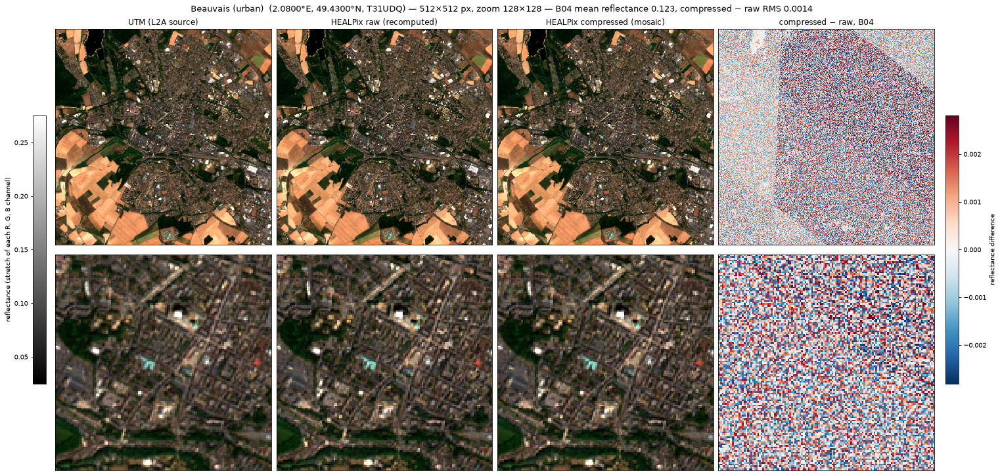

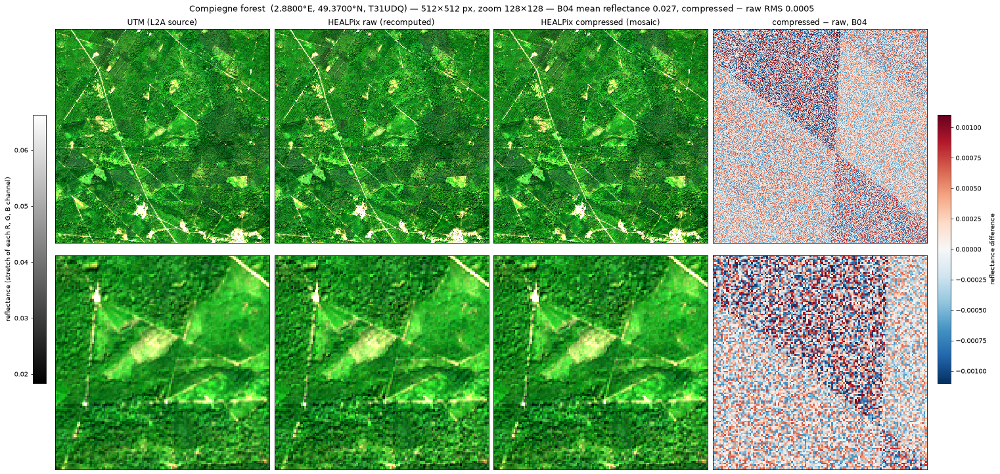

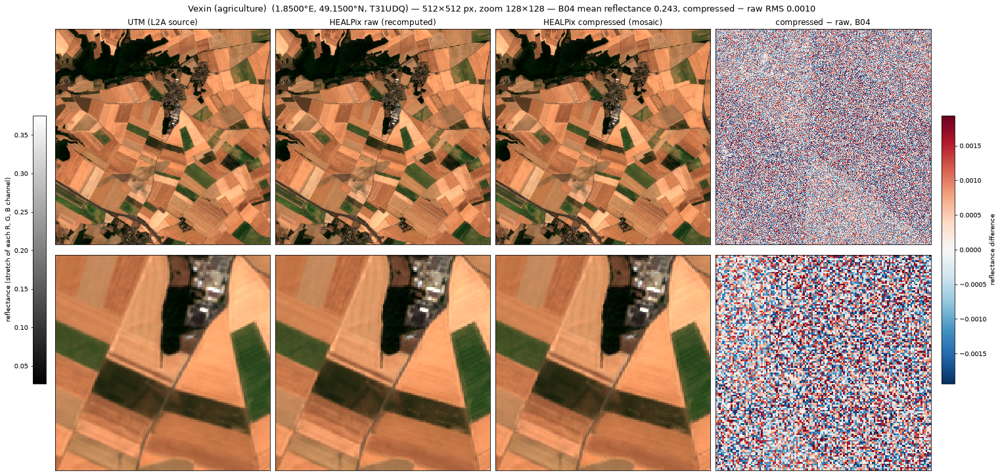

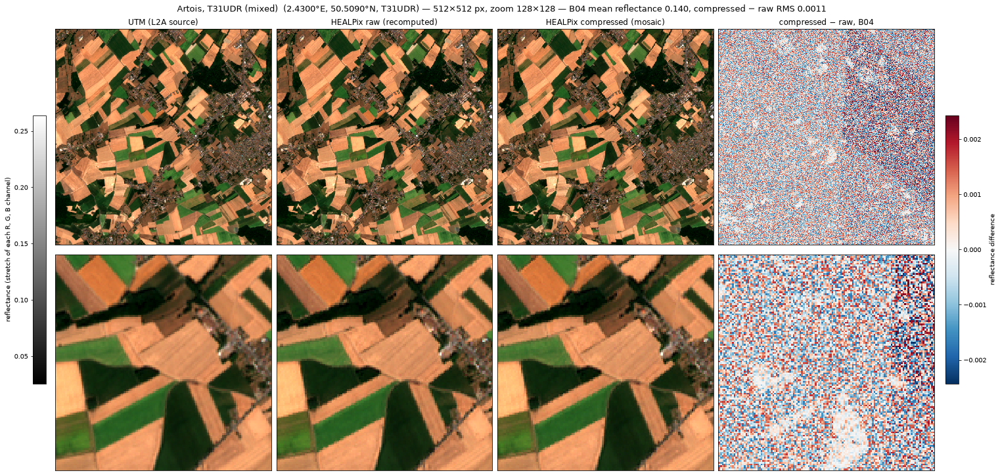

In [5]:
def rgb(stack, lo, hi):
    return np.clip((np.dstack([stack[2], stack[1], stack[0]]) - lo) / (hi - lo), 0, 1)

Z = slice(N // 2 - 64, N // 2 + 64)
for P in patches:
    lo, hi = np.nanpercentile(P["utm"][:3], [2, 98])
    d = P["nearest"]["codec"][2] - P["nearest"]["raw"][2]
    lim = np.percentile(np.abs(d), 99.5)
    fig, ax = plt.subplots(2, 4, figsize=(21, 10), constrained_layout=True)
    for row, sl in enumerate([(slice(None), slice(None)), (Z, Z)]):
        ax[row, 0].imshow(rgb(P["utm"][:, sl[0], sl[1]], lo, hi))
        ax[row, 1].imshow(rgb(P["nearest"]["raw"][:, sl[0], sl[1]], lo, hi))
        ax[row, 2].imshow(rgb(P["nearest"]["codec"][:, sl[0], sl[1]], lo, hi))
        im = ax[row, 3].imshow(d[sl], cmap="RdBu_r", vmin=-lim, vmax=lim)
    fig.colorbar(ScalarMappable(Normalize(lo, hi), "gray"), ax=ax[:, :3], shrink=0.6, location="left", pad=0.01,
                 label="reflectance (stretch of each R, G, B channel)")
    fig.colorbar(im, ax=ax[:, 3], shrink=0.6, label="reflectance difference")
    for a, t in zip(ax[0], ["UTM (L2A source)", "HEALPix raw (recomputed)", "HEALPix compressed (mosaic)",
                            "compressed − raw, B04"]):
        a.set_title(t)
    for a in ax.flat:
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{P['name']}  ({P['lon0']:.4f}°E, {P['lat0']:.4f}°N, {'+'.join(P['owner_tiles'])}) — 512×512 px, "
                 f"zoom 128×128 — B04 mean reflectance {np.nanmean(P['utm'][2]):.3f}, "
                 f"compressed − raw RMS {np.sqrt(np.mean(d ** 2)):.4f}", fontsize=13)
    plt.show()

## 5. HEALPix → UTM reprojection with `PSFResampler`

The conversion's `PSFResampler` models each UTM pixel as a Gaussian-weighted average of its `Npt` nearest HEALPix cells. The conversion solves this model in the least-squares sense to obtain the cells. The reverse operation, `invert`, applies the same model to the cells, and therefore predicts the UTM pixels.

The resampler is built on the patch pixel centres, with the same `Npt` and `threshold` as the conversion. The recomputed raw and the compressed fields are then reprojected. The residuals are:

- `UTM − PSF(raw)`: error of the UTM → HEALPix → UTM round trip alone;
- `UTM − PSF(compressed)`: the same, plus the codec error;
- `PSF(compressed) − PSF(raw)`: the codec error alone, seen on the UTM grid.

The table gives RMS values in units of 10⁻³ reflectance (1 unit = 10 DN), next to the mean and standard deviation of the UTM signal in the same units.

In [6]:
def reproject(P):
    t = time.time()
    R = PSFResampler(P["lon"].ravel(), P["lat"].ravel(), level=20, device="cpu", dtype=torch.float64,
                     verbose=False, **RES["init_params"])
    rc = R.cell_ids.cpu().numpy().astype(np.uint64)
    pc, pr = np.searchsorted(P["cells"], rc), np.searchsorted(P["rcells"], rc)
    assert np.all(P["cells"][np.minimum(pc, P["cells"].size - 1)] == rc), "cells missing in the mosaic"
    assert np.all(P["rcells"][np.minimum(pr, P["rcells"].size - 1)] == rc), "cells missing in the recompute"
    hv = {"raw": P["rvals"][:, pr], "codec": P["codec"][:, pc]}
    P["psf"] = {k: R.invert(v).reshape(len(BANDS), N, N) for k, v in hv.items()}
    P["hpx_err"] = hv["codec"] - hv["raw"]          # codec error in the HEALPix domain, cells used by this patch
    print(f"{P['name']:30s} K={R.K:,} cells, {time.time() - t:.1f}s")

for P in patches:
    reproject(P)

def rms(a, axis=(1, 2)):
    return np.sqrt(np.nanmean(a ** 2, axis=axis))

print(f"\nunits: 1e-3 reflectance{'':10s}" + "".join(f"{b:>9}" for b in BANDS))
for P in patches:
    lines = {
        "UTM signal mean":              np.nanmean(P["utm"], axis=(1, 2)),
        "UTM signal std":               np.nanstd(P["utm"], axis=(1, 2)),
        "RMS UTM − PSF(raw)":           rms(P["utm"] - P["psf"]["raw"]),
        "RMS UTM − PSF(compressed)":    rms(P["utm"] - P["psf"]["codec"]),
        "RMS PSF(compr.) − PSF(raw)":   rms(P["psf"]["codec"] - P["psf"]["raw"]),
        "RMS compr. − raw (HEALPix)":   rms(P["hpx_err"], axis=1),
    }
    print(P["name"])
    for k, v in lines.items():
        print(f"   {k:30s}" + "".join(f"{x * 1e3:9.2f}" for x in v))

Beauvais (urban)               K=679,237 cells, 1.5s


Compiegne forest               K=679,371 cells, 1.5s


Vexin (agriculture)            K=679,196 cells, 1.8s


Artois, T31UDR (mixed)         K=679,286 cells, 1.4s

units: 1e-3 reflectance                b02      b03      b04      b08
Beauvais (urban)
   UTM signal mean                   80.64   105.55   123.33   286.90
   UTM signal std                    41.52    49.35    74.87    92.38
   RMS UTM − PSF(raw)                 0.42     0.46     0.53     0.86
   RMS UTM − PSF(compressed)          0.74     0.81     0.94     1.57
   RMS PSF(compr.) − PSF(raw)         0.61     0.67     0.78     1.31
   RMS compr. − raw (HEALPix)         1.07     1.19     1.37     2.32
Compiegne forest
   UTM signal mean                   25.85    44.86    27.37   348.72
   UTM signal std                     7.24    10.19    12.67    63.95
   RMS UTM − PSF(raw)                 0.11     0.17     0.15     0.84
   RMS UTM − PSF(compressed)          0.24     0.35     0.31     1.63
   RMS PSF(compr.) − PSF(raw)         0.21     0.30     0.27     1.39
   RMS compr. − raw (HEALPix)         0.37     0.54     0.48     2.48
Ve

Residual maps for B04. The left panel shows the UTM data with its own colour bar; the three residual panels share one colour bar, in the same reflectance units, so the residual level can be read against the data level.

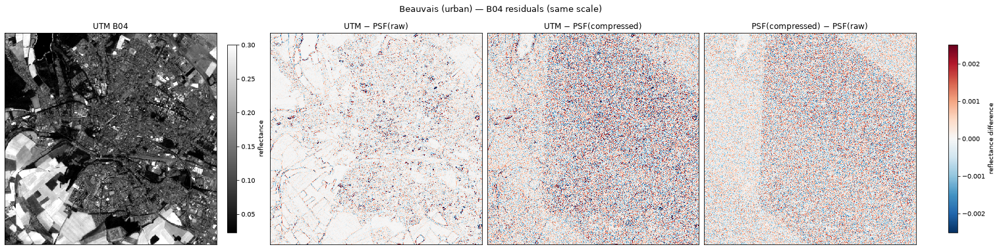

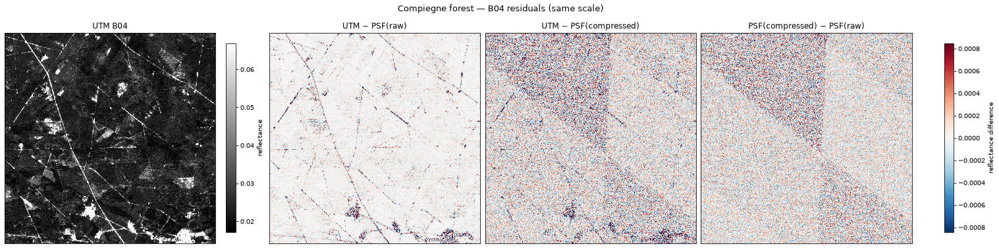

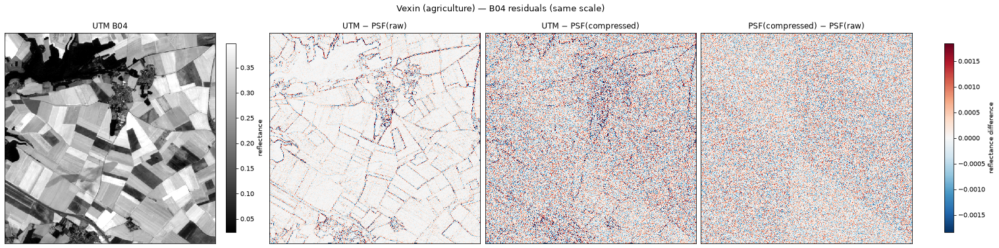

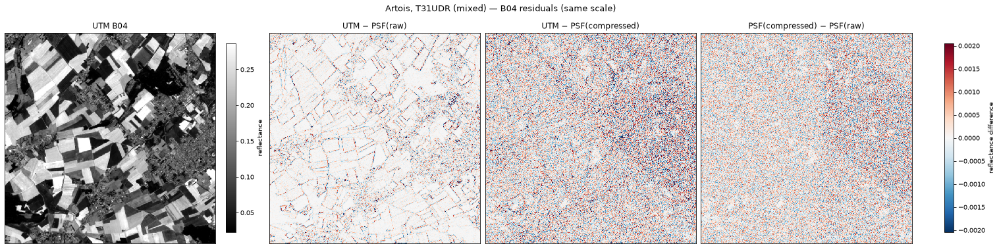

In [7]:
k = BANDS.index("b04")
for P in patches:
    imgs = [P["utm"][k] - P["psf"]["raw"][k], P["utm"][k] - P["psf"]["codec"][k],
            P["psf"]["codec"][k] - P["psf"]["raw"][k]]
    lim = np.nanpercentile(np.abs(imgs[1]), 99)
    fig, ax = plt.subplots(1, 4, figsize=(21, 5.4), constrained_layout=True)
    lo, hi = np.nanpercentile(P["utm"][k], [2, 98])
    h0 = ax[0].imshow(P["utm"][k], cmap="gray", vmin=lo, vmax=hi); ax[0].set_title("UTM B04")
    fig.colorbar(h0, ax=ax[0], shrink=0.8, label="reflectance")
    for a, im, t in zip(ax[1:], imgs, ["UTM − PSF(raw)", "UTM − PSF(compressed)", "PSF(compressed) − PSF(raw)"]):
        h = a.imshow(im, cmap="RdBu_r", vmin=-lim, vmax=lim); a.set_title(t)
    fig.colorbar(h, ax=ax[1:], shrink=0.8, label="reflectance difference")
    for a in ax:
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{P['name']} — B04 residuals (same scale)", fontsize=13)
    plt.show()

## 6. Power spectra of the residuals

2D power spectral density (Hann window, mean removed), averaged over rings of radial spatial frequency. Normalisation: the integral of the 2D PSD over the frequency plane equals the variance of the field, so the curves are in reflectance²·km². The top axis gives the wavelength. The UTM Nyquist frequency is 50 cycles/km (10 m pixels), marked by the dotted line.

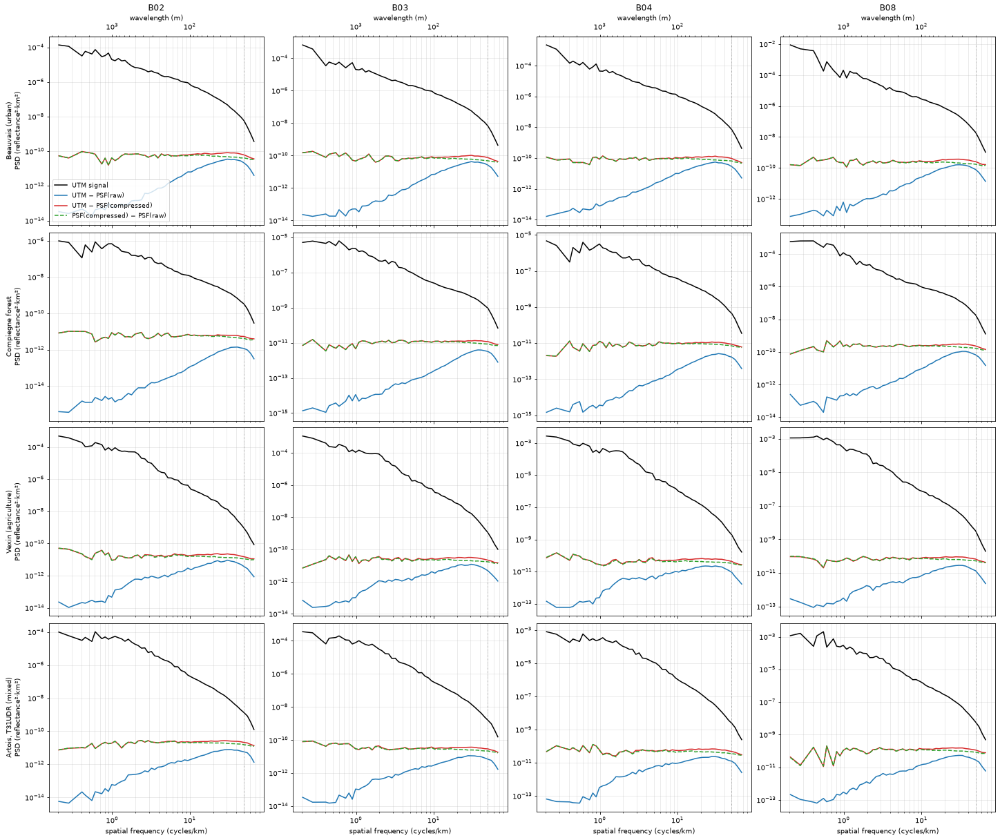

In [8]:
def radial_psd(img, dx=DX, nbins=60):
    a = np.array(img, float)
    a = np.where(np.isnan(a), np.nanmean(a), a)
    a -= a.mean()
    n = a.shape[0]
    w = np.outer(np.hanning(n), np.hanning(n))
    F = np.fft.fft2(a * w)
    psd2 = np.abs(F) ** 2 * dx * dx / (n * n * np.mean(w ** 2))        # refl² · m²
    f = np.fft.fftfreq(n, d=dx) * 1e3                                   # cycles/km
    kr = np.hypot(*np.meshgrid(f, f))
    edges = np.logspace(np.log10(1e3 / (n * dx)), np.log10(kr.max()), nbins + 1)
    idx = np.digitize(kr.ravel(), edges)
    p = np.bincount(idx, psd2.ravel(), minlength=nbins + 2)[1:nbins + 1]
    c = np.bincount(idx, minlength=nbins + 2)[1:nbins + 1]
    kc = np.sqrt(edges[1:] * edges[:-1])
    ok = c > 0
    return kc[ok], p[ok] / c[ok] / 1e6                                  # refl² · km²

CURVES = [("UTM signal", lambda P, i: P["utm"][i], "k", "-"),
          ("UTM − PSF(raw)", lambda P, i: P["utm"][i] - P["psf"]["raw"][i], "C0", "-"),
          ("UTM − PSF(compressed)", lambda P, i: P["utm"][i] - P["psf"]["codec"][i], "C3", "-"),
          ("PSF(compressed) − PSF(raw)", lambda P, i: P["psf"]["codec"][i] - P["psf"]["raw"][i], "C2", "--")]

fig, ax = plt.subplots(len(patches), len(BANDS), figsize=(20, 4.2 * len(patches)), sharex=True,
                       constrained_layout=True, squeeze=False)
for r, P in enumerate(patches):
    for c, b in enumerate(BANDS):
        a = ax[r, c]
        for lab, fn, col, ls in CURVES:
            kx, p = radial_psd(fn(P, c))
            a.loglog(kx, p, color=col, ls=ls, label=lab)
        a.axvline(50, color="gray", lw=0.8, ls=":")
        a.grid(True, which="both", alpha=0.3)
        if r == 0:
            a.set_title(b.upper())
            sec = a.secondary_xaxis("top", functions=(lambda k: 1e3 / np.maximum(k, 1e-9), lambda l: 1e3 / np.maximum(l, 1e-9)))
            sec.set_xlabel("wavelength (m)")
        if c == 0:
            a.set_ylabel(f"{P['name']}\nPSD (reflectance²·km²)")
        if r == len(patches) - 1:
            a.set_xlabel("spatial frequency (cycles/km)")
ax[0, 0].legend(fontsize=9, loc="lower left")
plt.show()

### Spectral ratio

Ratio `PSD(UTM − PSF(compressed)) / PSD(UTM − PSF(raw))` per band for the patches, on a logarithmic scale. A ratio close to 1 means that the codec adds almost nothing to the round-trip residual at that scale. A large ratio means that the codec error dominates the residual.

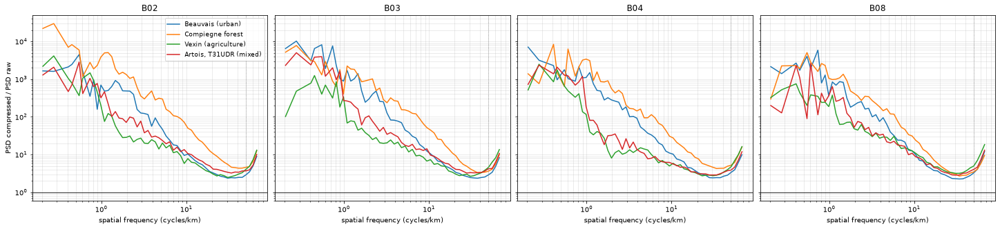

In [9]:
fig, ax = plt.subplots(1, len(BANDS), figsize=(20, 4.5), sharey=True, constrained_layout=True)
for c, b in enumerate(BANDS):
    for P in patches:
        k1, p_raw = radial_psd(P["utm"][c] - P["psf"]["raw"][c])
        _, p_cod = radial_psd(P["utm"][c] - P["psf"]["codec"][c])
        ax[c].loglog(k1, p_cod / p_raw, label=P["name"])
    ax[c].axhline(1, color="k", lw=0.8); ax[c].axvline(50, color="gray", lw=0.8, ls=":")
    ax[c].set_title(b.upper()); ax[c].set_xlabel("spatial frequency (cycles/km)"); ax[c].grid(True, which="both", alpha=0.3)
ax[0].set_ylabel("PSD compressed / PSD raw"); ax[0].legend(fontsize=9)
plt.show()

## 7. Tile boundary T31UDQ / T31UDR

The two MGRS tiles overlap by about 10 km in latitude on the same UTM 31N 10 m grid. In the mosaic, each level-11 parent cell takes its values from a single tile (`owner`). Two kinds of patches are tested here:

- **seam patches**, centred on the line where the owner switches from T31UDQ to T31UDR. They show whether the switch leaves a visible step in the mosaic. They need the parent cells on both sides of the seam to be written, and are skipped until then;
- **overlap patches**, inside the zone covered by both UTM tiles (owned by one tile only). They measure how much the two L2A tiles themselves differ where they overlap, which is the floor for any seam.

For each patch, the figure shows B04 from both UTM tiles, their difference, the owner tile of each pixel (with the level-11 cell outlines), the compressed mosaic, and the residuals of the reprojected mosaic against the per-pixel UTM reference and against each tile separately. Data panels share the grey reflectance colour bar; difference panels share the diverging one.

In [10]:
TQ, TR = TILES                      # south tile, north tile

def owner_switch_lat(lon, lats=np.arange(49.40, 49.95, 0.001)):
    p = np.asarray(lonlat_to_healpix(np.full(lats.size, lon), lats, 11, ellipsoid="WGS84"))
    own = np.array([owner.get(int(q), "") for q in p])
    i = np.nonzero((own[:-1] == TQ) & (own[1:] == TR))[0]
    return float(lats[i[0]]) if i.size else None

BOUNDARY_SITES = {}
for lon in (1.90, 2.40, 2.90):
    lat = owner_switch_lat(lon)
    if lat is not None:
        BOUNDARY_SITES[f"seam {lon:.2f}°E"] = (lon, lat)
for lon in (2.00, 2.70):
    BOUNDARY_SITES[f"overlap {lon:.2f}°E"] = (lon, 49.600)
for k, (lo_, la_) in BOUNDARY_SITES.items():
    print(f"{k:16s} centre {lo_:.4f}°E {la_:.4f}°N")

boundary = [P for P in (load_patch(k, *v) for k, v in BOUNDARY_SITES.items()) if P is not None]
for P in boundary:
    reproject(P)

seam 1.90°E      centre 1.9000°E 49.6670°N
seam 2.40°E      centre 2.4000°E 49.6760°N
seam 2.90°E      centre 2.9000°E 49.6610°N
overlap 2.00°E   centre 2.0000°E 49.6000°N
overlap 2.70°E   centre 2.7000°E 49.6000°N
seam 1.90°E                    SKIPPED: 5/10 parent cells not written
seam 2.40°E                    SKIPPED: 4/8 parent cells not written
seam 2.90°E                    SKIPPED: 3/7 parent cells not written


overlap 2.00°E                 tiles ['T31UDQ'], 10 parent cells, 2,621,440 cells, 0.00% UTM fill, 14.5s


overlap 2.70°E                 tiles ['T31UDQ'], 7 parent cells, 1,835,008 cells, 0.00% UTM fill, 14.5s


overlap 2.00°E                 K=679,228 cells, 1.5s


overlap 2.70°E                 K=679,319 cells, 1.4s


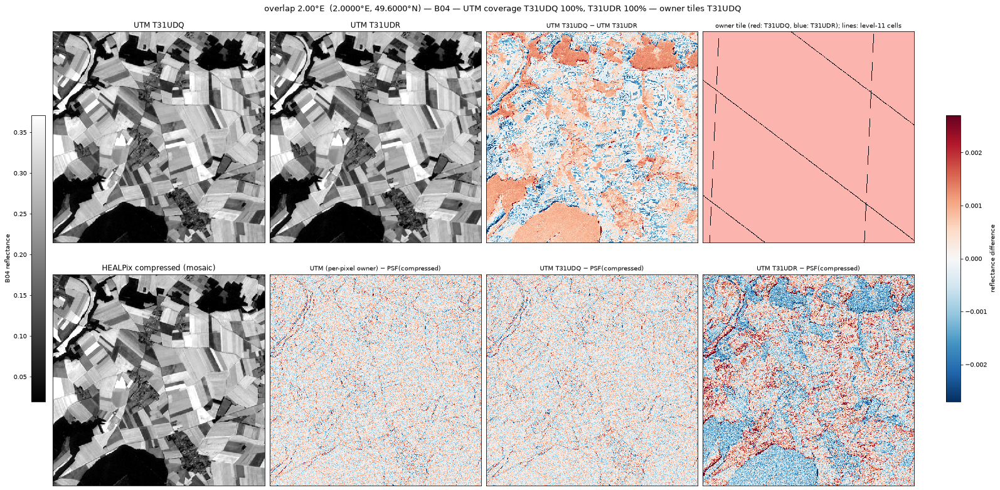

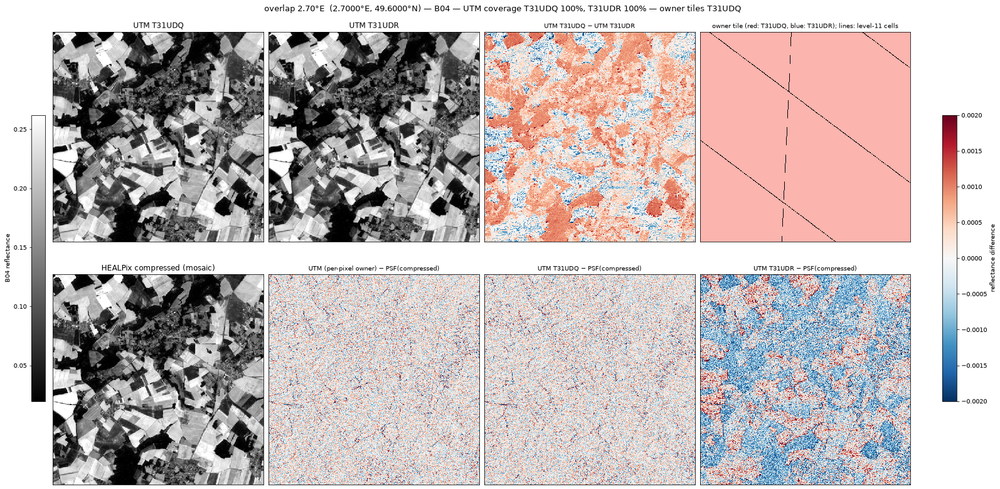

units: 1e-3 reflectance                            b02      b03      b04      b08
overlap 2.00°E
   RMS T31UDQ − T31UDR (overlap)                  1.35     0.82     0.95     1.38
   RMS UTM − PSF(raw)                             0.20     0.26     0.38     0.58
   RMS UTM − PSF(compressed)                      0.39     0.50     0.71     1.05
   RMS T31UDQ − PSF(compressed)                   0.39     0.50     0.71     1.05
   RMS T31UDR − PSF(compressed)                   1.42     0.98     1.22     1.75
overlap 2.70°E
   RMS T31UDQ − T31UDR (overlap)                  1.42     0.85     0.69     1.09
   RMS UTM − PSF(raw)                             0.20     0.24     0.34     0.63
   RMS UTM − PSF(compressed)                      0.37     0.44     0.62     1.10
   RMS T31UDQ − PSF(compressed)                   0.37     0.44     0.62     1.10
   RMS T31UDR − PSF(compressed)                   1.48     0.98     0.96     1.57


In [11]:
k = BANDS.index("b04")
for P in boundary:
    uq, ur, comp = P["utm_tiles"][TQ][k], P["utm_tiles"][TR][k], P["utm"][k]
    psf_c = P["psf"]["codec"][k]
    diffs = {f"UTM {TQ} − UTM {TR}": uq - ur,
             "UTM (per-pixel owner) − PSF(compressed)": comp - psf_c,
             f"UTM {TQ} − PSF(compressed)": uq - psf_c,
             f"UTM {TR} − PSF(compressed)": ur - psf_c}
    lim = np.nanpercentile(np.abs(np.concatenate([v[np.isfinite(v)] for v in diffs.values()])), 99)
    lo, hi = np.nanpercentile(comp, [2, 98])
    fig, ax = plt.subplots(2, 4, figsize=(22, 11), constrained_layout=True)
    data_axes = [ax[0, 0], ax[0, 1], ax[1, 0]]
    for a, im, t in zip(data_axes, [uq, ur, P["nearest"]["codec"][k] if "nearest" in P else psf_c],
                        [f"UTM {TQ}", f"UTM {TR}", "HEALPix compressed (mosaic)"]):
        hg = a.imshow(im, cmap="gray", vmin=lo, vmax=hi); a.set_title(t)
    diff_axes = [ax[0, 2], ax[1, 1], ax[1, 2], ax[1, 3]]
    for a, (t, im) in zip(diff_axes, diffs.items()):
        hd = a.imshow(im, cmap="RdBu_r", vmin=-lim, vmax=lim); a.set_title(t, fontsize=10)
    own_num = (P["own"] == TR).astype(float)
    edge = np.zeros(P["parent"].shape, bool)
    edge[1:, :] |= P["parent"][1:, :] != P["parent"][:-1, :]
    edge[:, 1:] |= P["parent"][:, 1:] != P["parent"][:, :-1]
    ax[0, 3].imshow(own_num, cmap="Pastel1", vmin=0, vmax=8)
    ax[0, 3].imshow(np.ma.masked_where(~edge, edge), cmap="gray_r", vmin=0, vmax=1)
    ax[0, 3].set_title(f"owner tile (red: {TQ}, blue: {TR}); lines: level-11 cells", fontsize=10)
    fig.colorbar(hg, ax=data_axes, location="left", shrink=0.6, pad=0.01, label="B04 reflectance")
    fig.colorbar(hd, ax=diff_axes, location="right", shrink=0.6, label="reflectance difference")
    for a in ax.flat:
        a.set_xticks([]); a.set_yticks([])
    cov = {t: 100 * np.isfinite(P["utm_tiles"][t][k]).mean() for t in TILES}
    fig.suptitle(f"{P['name']}  ({P['lon0']:.4f}°E, {P['lat0']:.4f}°N) — B04 — UTM coverage "
                 f"{TQ} {cov[TQ]:.0f}%, {TR} {cov[TR]:.0f}% — owner tiles {'+'.join(P['owner_tiles'])}", fontsize=13)
    plt.show()

print(f"units: 1e-3 reflectance{'':22s}" + "".join(f"{b:>9}" for b in BANDS))
for P in boundary:
    uq, ur = P["utm_tiles"][TQ], P["utm_tiles"][TR]
    print(P["name"])
    for lab, v in [(f"RMS {TQ} − {TR} (overlap)", uq - ur),
                   ("RMS UTM − PSF(raw)", P["utm"] - P["psf"]["raw"]),
                   ("RMS UTM − PSF(compressed)", P["utm"] - P["psf"]["codec"]),
                   (f"RMS {TQ} − PSF(compressed)", uq - P["psf"]["codec"]),
                   (f"RMS {TR} − PSF(compressed)", ur - P["psf"]["codec"])]:
        print(f"   {lab:42s}" + "".join(f"{x * 1e3:9.2f}" for x in rms(v)))

Power spectra on the overlap patches (both tiles cover the whole patch): the difference between the two L2A tiles is compared with the residual of the compressed mosaic and with the signal.

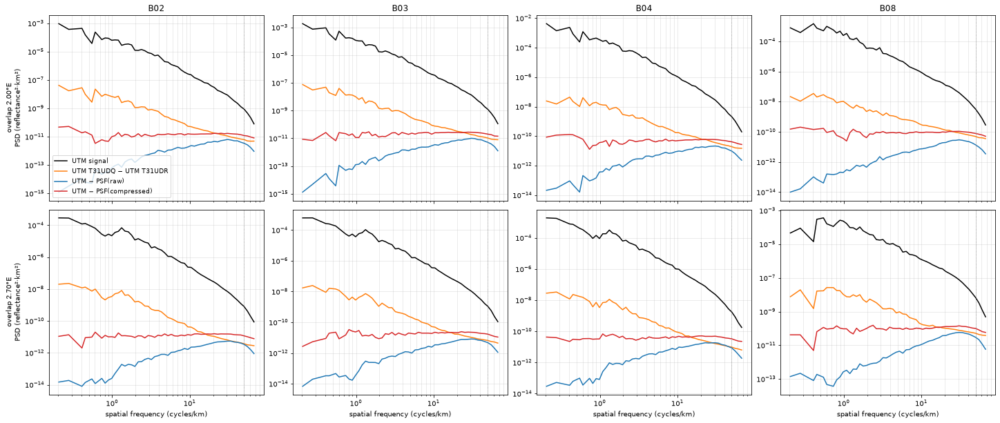

In [12]:
full = [P for P in boundary if all(np.isfinite(P["utm_tiles"][t]).all() for t in TILES)]
if not full:
    print("no boundary patch fully covered by both tiles")
else:
    fig, ax = plt.subplots(len(full), len(BANDS), figsize=(20, 4.2 * len(full)), sharex=True,
                           constrained_layout=True, squeeze=False)
    for r, P in enumerate(full):
        for c, b in enumerate(BANDS):
            a = ax[r, c]
            for lab, im, col, ls in [("UTM signal", P["utm"][c], "k", "-"),
                                     (f"UTM {TQ} − UTM {TR}", P["utm_tiles"][TQ][c] - P["utm_tiles"][TR][c], "C1", "-"),
                                     ("UTM − PSF(raw)", P["utm"][c] - P["psf"]["raw"][c], "C0", "-"),
                                     ("UTM − PSF(compressed)", P["utm"][c] - P["psf"]["codec"][c], "C3", "-")]:
                kx, p = radial_psd(im)
                a.loglog(kx, p, color=col, ls=ls, label=lab)
            a.axvline(50, color="gray", lw=0.8, ls=":"); a.grid(True, which="both", alpha=0.3)
            if r == 0:
                a.set_title(b.upper())
            if c == 0:
                a.set_ylabel(f"{P['name']}\nPSD (reflectance²·km²)")
            if r == len(full) - 1:
                a.set_xlabel("spatial frequency (cycles/km)")
    ax[0, 0].legend(fontsize=9, loc="lower left")
    plt.show()